# Deep Learning Practical Exam — Set A


In [10]:
# Install the packages used in this practical
%pip install -q numpy pandas matplotlib scikit-learn tensorflow opencv-python transformers torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
# Import the common libraries
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.makedirs("outputs", exist_ok=True)

## Step 1 — ANN: Diabetes Classification

Dataset: Pima Indians Diabetes (`diabetes.csv`). Place the CSV in the notebook folder before running this section. The expected target column is `Outcome`.

In [12]:

# Load and inspect the diabetes dataset
import os
import pandas as pd

diabetes_url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

if os.path.exists("diabetes.csv"):
    df_diabetes = pd.read_csv("diabetes.csv")
else:
    df_diabetes = pd.read_csv(diabetes_url)
    df_diabetes.to_csv("diabetes.csv", index=False)

print("Dataset loaded successfully!")
print("Shape:", df_diabetes.shape)
display(df_diabetes.head())

print("\nMissing values:\n", df_diabetes.isnull().sum())


Dataset loaded successfully!
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [13]:
# Replace impossible zero values with each column median
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in zero_columns:
    if col in df_diabetes.columns:
        df_diabetes[col] = df_diabetes[col].replace(0, np.nan)
        df_diabetes[col] = df_diabetes[col].fillna(df_diabetes[col].median())
print(df_diabetes.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [14]:

# Check the installed TensorFlow version
%pip show tensorflow


Name: tensorflow
Version: 2.21.0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: c:\Users\HP\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, setuptools, six, termcolor, typing_extensions, wrapt
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [15]:

# Test the TensorFlow installation
import tensorflow as tf
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [ ]:

# Split, scale, and prepare the ANN data
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

SEED = 42

X = df_diabetes.drop(columns=["Outcome"])
y = df_diabetes["Outcome"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

scaler_ann = StandardScaler()
X_train_scaled = scaler_ann.fit_transform(X_train)
X_test_scaled = scaler_ann.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)
print("ANN data preparation completed successfully.")


Training data: (614, 8)
Testing data: (154, 8)
ANN data preparation completed successfully.


In [17]:
# Build and compile the ANN
ann_model = Sequential([
    Dense(16, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])
ann_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

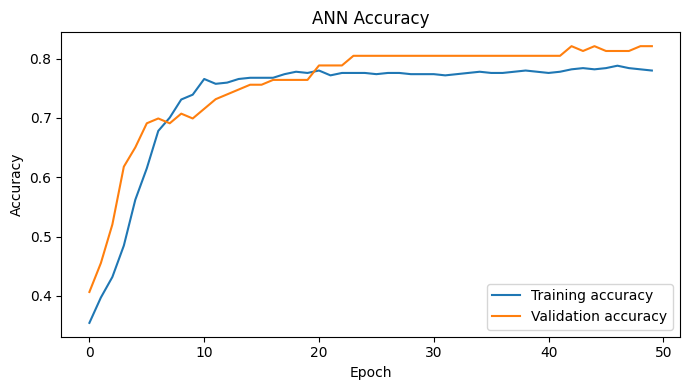

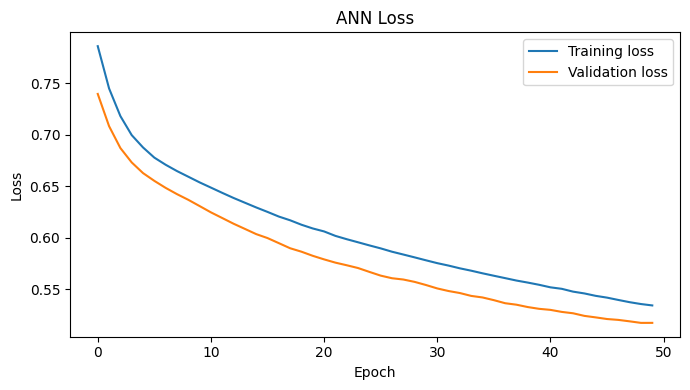

In [18]:
# Train the ANN and display its learning curves
ann_history = ann_model.fit(
    X_train_scaled, y_train, epochs=50, batch_size=32,
    validation_split=0.2, verbose=0
)
plt.figure(figsize=(7, 4))
plt.plot(ann_history.history["accuracy"], label="Training accuracy")
plt.plot(ann_history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(ann_history.history["loss"], label="Training loss")
plt.plot(ann_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# Evaluate and save the ANN model
ann_prob = ann_model.predict(X_test_scaled, verbose=0).ravel()
ann_pred = (ann_prob >= 0.5).astype(int)
print("Test Accuracy:", round(accuracy_score(y_test, ann_pred), 4))
print("Precision:", round(precision_score(y_test, ann_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, ann_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, ann_pred, zero_division=0), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, ann_pred))
ann_model.save("ann_diabetes_model.h5")

Test Accuracy: 0.7013
Precision: 0.5833
Recall: 0.5185
F1-Score: 0.549
Confusion Matrix:
 [[80 20]
 [26 28]]


**ANN reflection**

- The input layer receives the eight patient features.
- The hidden Dense layers learn patterns in the input data. ReLU adds non-linearity.
- The 16-neuron layer learns broader patterns; the 8-neuron layer compresses them before prediction.
- The sigmoid output gives a score between 0 and 1 that can be treated as the estimated probability of diabetes.

## Step 2 — OpenCV: Image Preprocessing

This section creates five simple sample images locally so the pipeline can run without relying on separate image downloads. If you have your own five images, replace the sample-image creation cell with `cv2.imread()` calls for those files.

In [20]:
# Create five sample images for a reproducible preprocessing demonstration
import cv2
sample_images = []
for i in range(5):
    canvas = np.full((180, 180, 3), 245, dtype=np.uint8)
    cv2.circle(canvas, (90, 90), 35 + i * 3, (40 + i * 20, 150, 220 - i * 20), -1)
    cv2.rectangle(canvas, (20 + i * 3, 20), (65 + i * 3, 60), (60, 180, 70), 3)
    cv2.line(canvas, (15, 150 - i * 5), (160, 30 + i * 5), (180, 60, 90), 4)
    sample_images.append(canvas)
print("Number of images:", len(sample_images))

Number of images: 5


Image 1 shape (height, width, channels): (180, 180, 3)
Image 2 shape (height, width, channels): (180, 180, 3)
Image 3 shape (height, width, channels): (180, 180, 3)
Image 4 shape (height, width, channels): (180, 180, 3)
Image 5 shape (height, width, channels): (180, 180, 3)


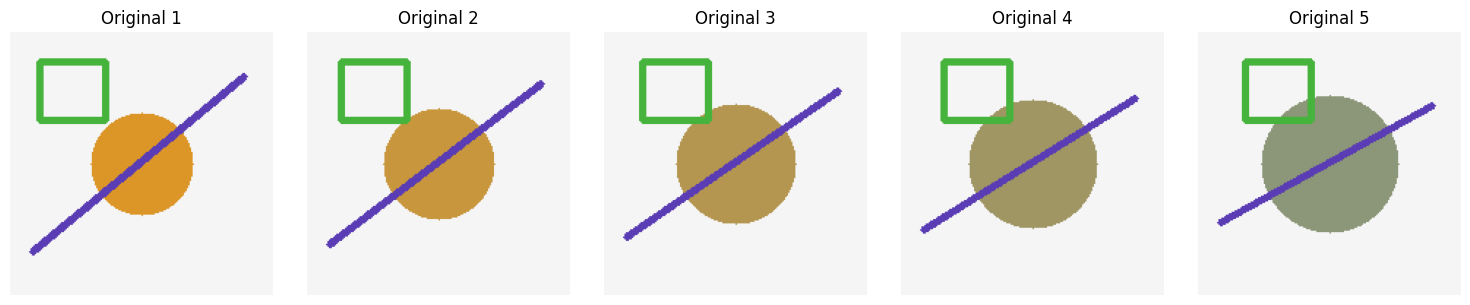

In [21]:
# Display the original images and their shapes
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, img in enumerate(sample_images):
    print(f"Image {i + 1} shape (height, width, channels):", img.shape)
    axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i].set_title(f"Original {i + 1}")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [22]:
# Resize, convert to grayscale, blur, detect edges, and mark the largest contour
opencv_results = []
for img in sample_images:
    resized = cv2.resize(img, (128, 128))
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 100, 200)
    contours, _ = cv2.findContours(edges.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contour_img = resized.copy()
    if contours:
        largest = max(contours, key=cv2.contourArea)
        x, y0, w, h = cv2.boundingRect(largest)
        cv2.rectangle(contour_img, (x, y0), (x + w, y0 + h), (0, 255, 0), 2)
    opencv_results.append((resized, gray, edges, contour_img))

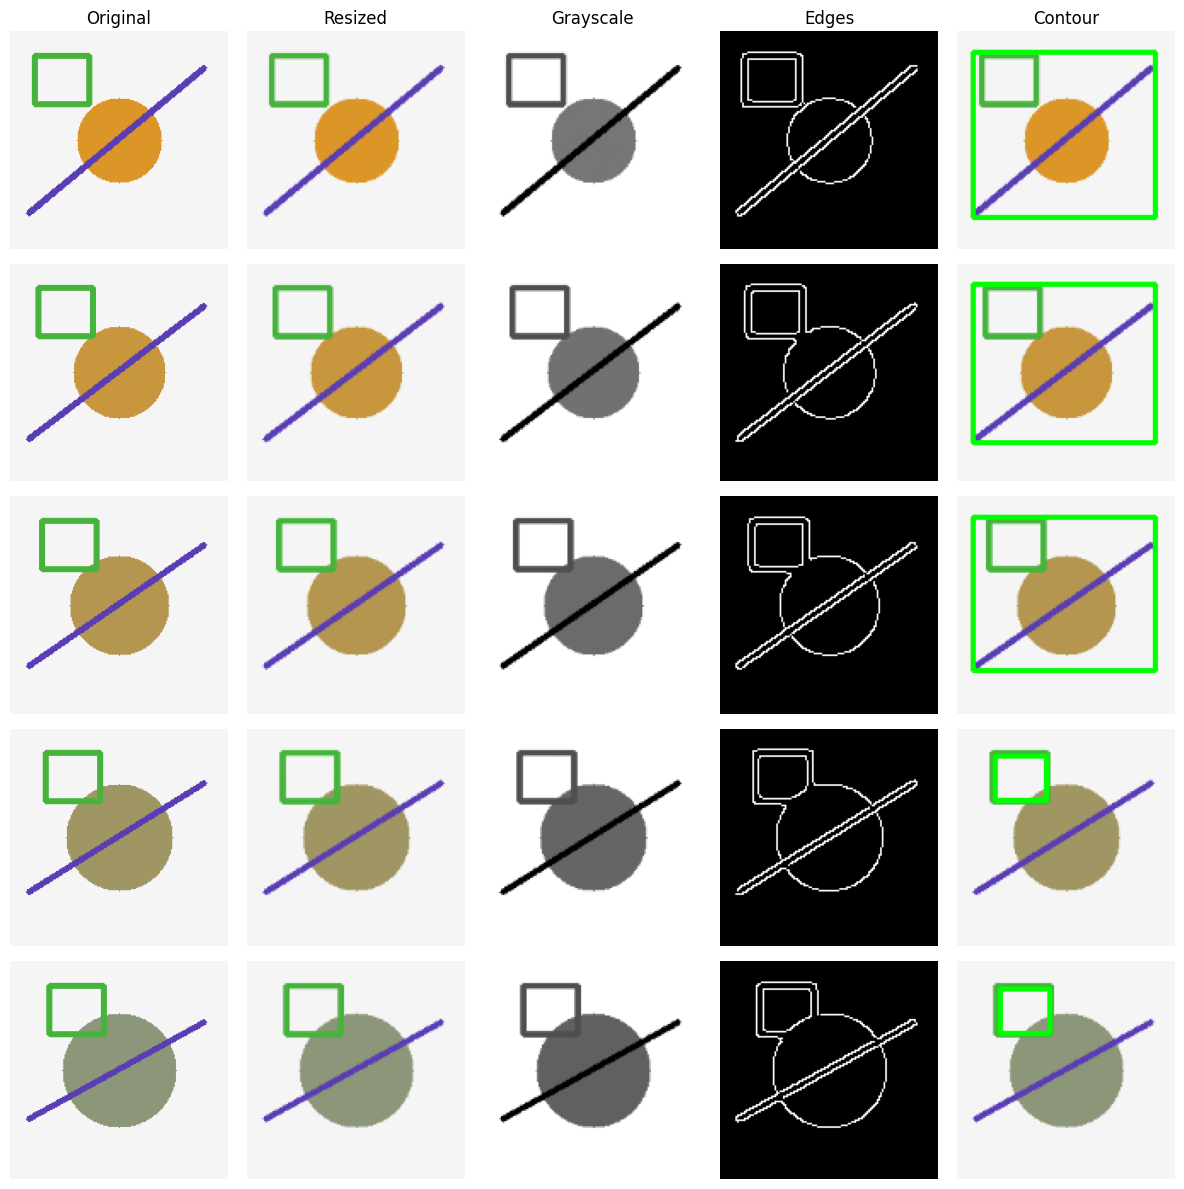

In [23]:
# Show and save the five-by-five preprocessing grid
fig, axes = plt.subplots(5, 5, figsize=(12, 12))
for i, (original, (resized, gray, edges, contour_img)) in enumerate(zip(sample_images, opencv_results)):
    images = [
        cv2.cvtColor(original, cv2.COLOR_BGR2RGB),
        cv2.cvtColor(resized, cv2.COLOR_BGR2RGB),
        gray,
        edges,
        cv2.cvtColor(contour_img, cv2.COLOR_BGR2RGB)
    ]
    titles = ["Original", "Resized", "Grayscale", "Edges", "Contour"]
    for j, image in enumerate(images):
        axes[i, j].imshow(image, cmap="gray" if j in [2, 3] else None)
        if i == 0:
            axes[i, j].set_title(titles[j])
        axes[i, j].axis("off")
    cv2.imwrite(f"outputs/opencv_image_{i+1}_resized.png", resized)
    cv2.imwrite(f"outputs/opencv_image_{i+1}_gray.png", gray)
    cv2.imwrite(f"outputs/opencv_image_{i+1}_edges.png", edges)
    cv2.imwrite(f"outputs/opencv_image_{i+1}_contour.png", contour_img)
plt.tight_layout()
plt.savefig("outputs/opencv_preprocessing_grid.png", dpi=150, bbox_inches="tight")
plt.show()

**OpenCV reflection**

- Resizing makes image dimensions consistent.
- Grayscale reduces three color channels to one intensity channel.
- Gaussian blur reduces small noise before edge detection.
- Canny identifies strong edges in the image.
- Contours describe connected boundaries; the largest contour is enclosed in a green rectangle when one is found.

## Step 3 — CNN: CIFAR-10 Image Classification

The exam asks for 20,000 training images and 4,000 test images, with pixel values scaled to `[0, 1]`.

In [24]:
# Load CIFAR-10 and select the required subset
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
(X_train_cifar, y_train_cifar), (X_test_cifar, y_test_cifar) = cifar10.load_data()
X_train_cifar = X_train_cifar[:20000].astype("float32") / 255.0
y_train_cifar = y_train_cifar[:20000].ravel()
X_test_cifar = X_test_cifar[:4000].astype("float32") / 255.0
y_test_cifar = y_test_cifar[:4000].ravel()
y_train_cat = to_categorical(y_train_cifar, 10)
y_test_cat = to_categorical(y_test_cifar, 10)
class_names = ["airplane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print(X_train_cifar.shape, X_test_cifar.shape)

(20000, 32, 32, 3) (4000, 32, 32, 3)


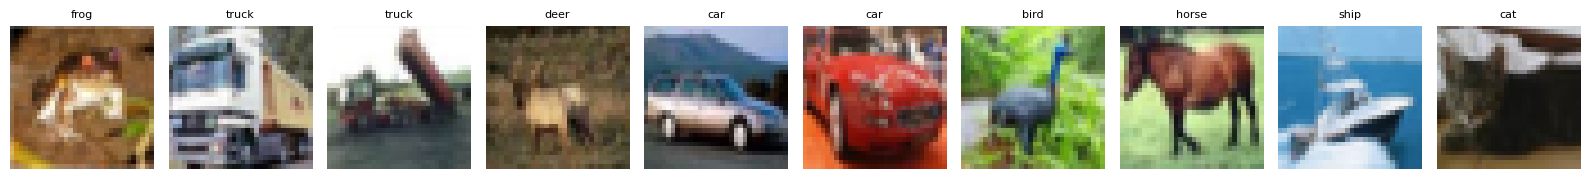

In [25]:
# Display ten CIFAR-10 training images with class labels
fig, axes = plt.subplots(1, 10, figsize=(16, 3))
for i, ax in enumerate(axes):
    ax.imshow(X_train_cifar[i])
    ax.set_title(class_names[y_train_cifar[i]], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [26]:
# Build and compile the CNN
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten
cnn_model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])
cnn_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.3685 - loss: 1.7430 - val_accuracy: 0.4640 - val_loss: 1.4774
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.5010 - loss: 1.3885 - val_accuracy: 0.4955 - val_loss: 1.3913
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.5608 - loss: 1.2481 - val_accuracy: 0.5320 - val_loss: 1.3569
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.5965 - loss: 1.1449 - val_accuracy: 0.5590 - val_loss: 1.3408
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.6276 - loss: 1.0641 - val_accuracy: 0.6020 - val_loss: 1.1592
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.6492 - loss: 1.0027 - val_accuracy: 0.5920 - val_loss: 1.1792
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.6721 - loss: 0.9472 - val_accuracy: 0.6135 - val_loss: 1.1241
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.6921 - loss: 0.8864 - val

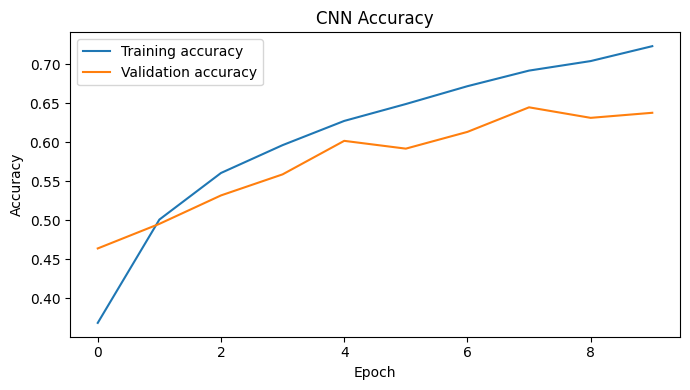

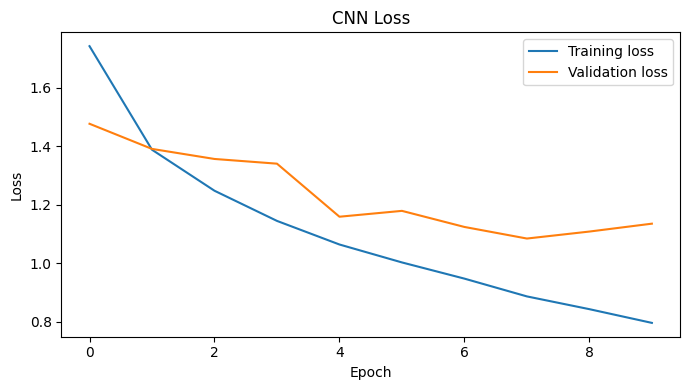

In [27]:
# Train the CNN and plot accuracy and loss
cnn_history = cnn_model.fit(
    X_train_cifar, y_train_cat, epochs=10, batch_size=64,
    validation_split=0.1, verbose=1
)
plt.figure(figsize=(7, 4))
plt.plot(cnn_history.history["accuracy"], label="Training accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(cnn_history.history["loss"], label="Training loss")
plt.plot(cnn_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
# Evaluate the CNN and print its classification report
from sklearn.metrics import classification_report
cnn_loss, cnn_accuracy = cnn_model.evaluate(X_test_cifar, y_test_cat, verbose=0)
cnn_pred = np.argmax(cnn_model.predict(X_test_cifar, verbose=0), axis=1)
print("Test Accuracy:", round(float(cnn_accuracy), 4))
print(classification_report(y_test_cifar, cnn_pred, target_names=class_names, zero_division=0))

Test Accuracy: 0.6335
              precision    recall  f1-score   support

    airplane       0.83      0.47      0.60       389
         car       0.82      0.72      0.77       392
        bird       0.52      0.47      0.49       426
         cat       0.49      0.40      0.44       389
        deer       0.59      0.50      0.54       400
         dog       0.55      0.54      0.54       388
        frog       0.60      0.86      0.71       396
       horse       0.59      0.80      0.68       397
        ship       0.71      0.84      0.77       408
       truck       0.72      0.73      0.72       415

    accuracy                           0.63      4000
   macro avg       0.64      0.63      0.63      4000
weighted avg       0.64      0.63      0.63      4000



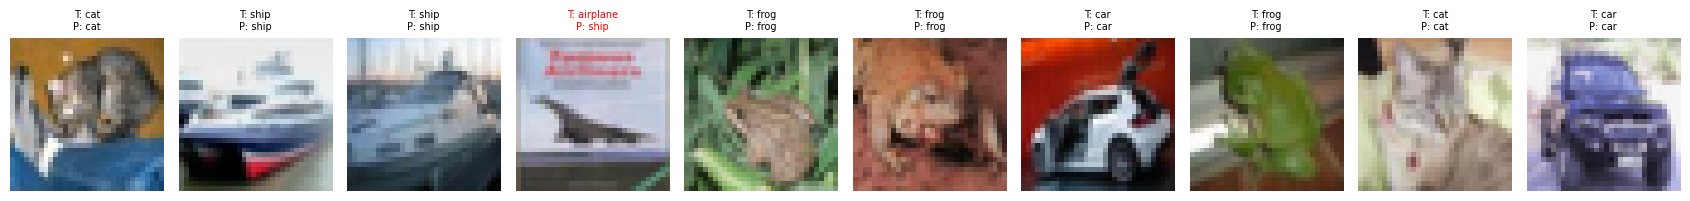

In [29]:
# Show ten test predictions and mark incorrect predictions in red
sample_indices = np.arange(10)
sample_probs = cnn_model.predict(X_test_cifar[sample_indices], verbose=0)
sample_preds = np.argmax(sample_probs, axis=1)
fig, axes = plt.subplots(1, 10, figsize=(17, 3))
for i, ax in enumerate(axes):
    true_name = class_names[y_test_cifar[i]]
    pred_name = class_names[sample_preds[i]]
    ax.imshow(X_test_cifar[i])
    ax.set_title(f"T: {true_name}\nP: {pred_name}", color="red" if true_name != pred_name else "black", fontsize=7)
    ax.axis("off")
plt.tight_layout()
plt.show()
cnn_model.save("cnn_cifar10_model.h5")

**CNN reflection**

- Conv2D learns local visual patterns such as edges and textures.
- MaxPooling reduces feature-map size and keeps strong activations.
- Flatten converts the feature maps into a one-dimensional vector for the Dense layers.

## Step 4 — RNN: Monthly Airline Passenger Forecasting

Dataset: the airline-passengers CSV specified in the exam PDF. The split is chronological; the sequence order is not shuffled.

     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121


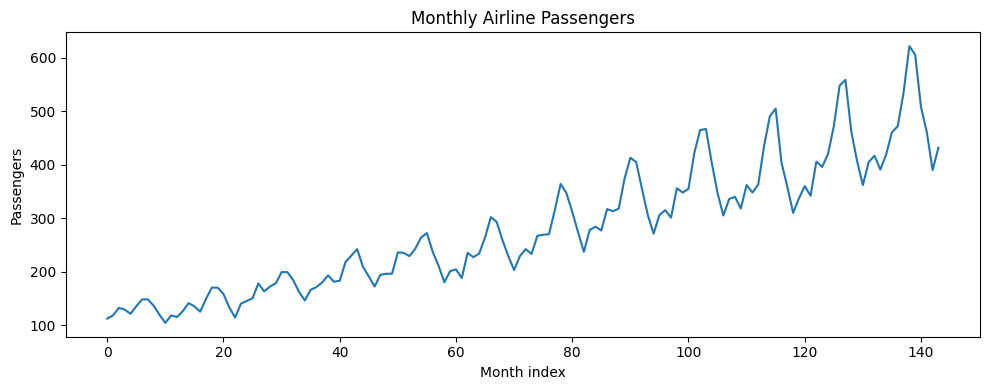

In [30]:
# Load and plot the airline passenger time series
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
airline_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
airline_df = pd.read_csv(airline_url)
print(airline_df.head())
plt.figure(figsize=(10, 4))
plt.plot(airline_df["Passengers"])
plt.title("Monthly Airline Passengers")
plt.xlabel("Month index")
plt.ylabel("Passengers")
plt.tight_layout()
plt.show()

In [31]:
# Scale passenger counts and create 12-month sequences
passengers = airline_df[["Passengers"]].values.astype("float32")
scaler_rnn = MinMaxScaler()
passengers_scaled = scaler_rnn.fit_transform(passengers)
look_back = 12
X_seq, y_seq = [], []
for i in range(len(passengers_scaled) - look_back):
    X_seq.append(passengers_scaled[i:i + look_back, 0])
    y_seq.append(passengers_scaled[i + look_back, 0])
X_seq = np.array(X_seq).reshape(-1, look_back, 1)
y_seq = np.array(y_seq)
split_idx = int(len(X_seq) * 0.8)
X_train_rnn, X_test_rnn = X_seq[:split_idx], X_seq[split_idx:]
y_train_rnn, y_test_rnn = y_seq[:split_idx], y_seq[split_idx:]
print("Train:", X_train_rnn.shape, "Test:", X_test_rnn.shape)

Train: (105, 12, 1) Test: (27, 12, 1)


In [32]:
# Build and compile the SimpleRNN model
from tensorflow.keras.layers import SimpleRNN
rnn_model = Sequential([
    SimpleRNN(50, activation="tanh", input_shape=(look_back, 1)),
    Dense(1)
])
rnn_model.compile(optimizer="adam", loss="mse")
rnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

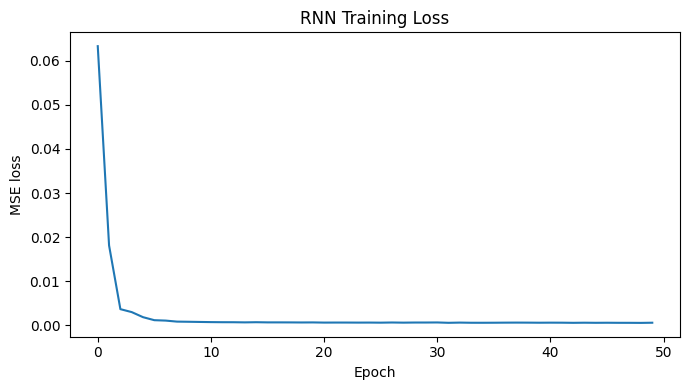

In [33]:
# Train the RNN and plot training loss
rnn_history = rnn_model.fit(X_train_rnn, y_train_rnn, epochs=50, batch_size=16, verbose=0)
plt.figure(figsize=(7, 4))
plt.plot(rnn_history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("RNN Training Loss")
plt.tight_layout()
plt.show()

Test RMSE: 32.08


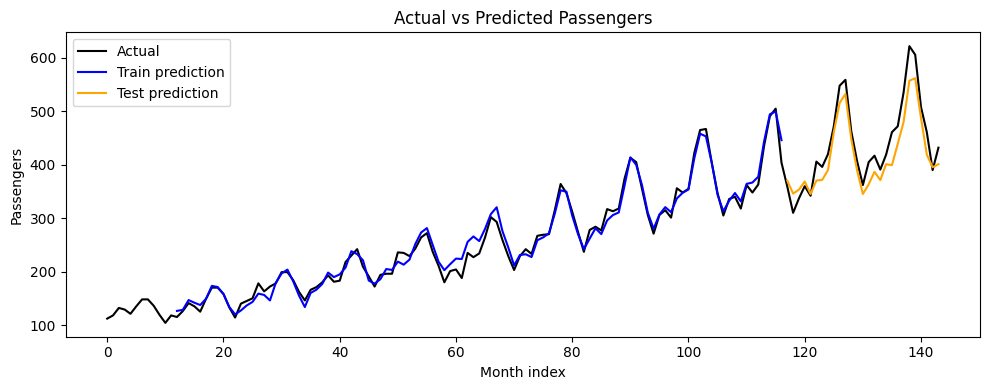

In [34]:
# Predict passenger counts, calculate RMSE, and save the RNN
train_pred_scaled = rnn_model.predict(X_train_rnn, verbose=0)
test_pred_scaled = rnn_model.predict(X_test_rnn, verbose=0)
train_pred = scaler_rnn.inverse_transform(train_pred_scaled)
test_pred = scaler_rnn.inverse_transform(test_pred_scaled)
y_train_actual = scaler_rnn.inverse_transform(y_train_rnn.reshape(-1, 1))
y_test_actual = scaler_rnn.inverse_transform(y_test_rnn.reshape(-1, 1))
rmse_rnn = np.sqrt(mean_squared_error(y_test_actual, test_pred))
print("Test RMSE:", round(float(rmse_rnn), 2))
plt.figure(figsize=(10, 4))
plt.plot(np.arange(len(passengers)), passengers, label="Actual", color="black")
train_positions = np.arange(look_back, look_back + len(train_pred))
test_positions = np.arange(look_back + len(train_pred), look_back + len(train_pred) + len(test_pred))
plt.plot(train_positions, train_pred.ravel(), label="Train prediction", color="blue")
plt.plot(test_positions, test_pred.ravel(), label="Test prediction", color="orange")
plt.xlabel("Month index")
plt.ylabel("Passengers")
plt.title("Actual vs Predicted Passengers")
plt.legend()
plt.tight_layout()
plt.show()
rnn_model.save("rnn_airline_model.h5")

**RNN reflection**

- A recurrent connection carries information from earlier time steps into later time steps.
- The data must not be shuffled because future months should not be used to predict earlier months.
- RMSE measures the typical size of prediction errors in passenger-count units; lower is better.

## Step 5 — Transformers: Sentiment Classification

The pre-trained Hugging Face sentiment pipeline is used for inference only. The model returns positive or negative labels, so neutral examples may still be forced into one of those two labels.

In [35]:
# Create 25 review sentences and their manually assigned sentiments
from transformers import pipeline
reviews = [
    "The film was absolutely brilliant and moving.",
    "The actors gave outstanding performances.",
    "I loved the story from beginning to end.",
    "The music made the movie even better.",
    "A wonderful film that I would watch again.",
    "The direction was excellent and creative.",
    "The comedy was clever and enjoyable.",
    "The visuals were beautiful and impressive.",
    "This movie made my evening special.",
    "A powerful and unforgettable experience.",
    "Worst movie I have ever seen.",
    "The story was boring and confusing.",
    "The acting was terrible throughout.",
    "I regret spending money on this film.",
    "The dialogues were weak and dull.",
    "Nothing in this movie worked for me.",
    "The pacing was painfully slow.",
    "The ending was disappointing.",
    "The film was noisy and badly edited.",
    "I would not recommend this movie.",
    "The acting was decent but the plot was weak.",
    "The movie had some good and bad moments.",
    "The story was average and predictable.",
    "The film was timepass only.",
    "Total bakwaas picture, but the songs were okay."
]
true_sentiments = ["POS"] * 10 + ["NEG"] * 10 + ["NEU"] * 5
print("Number of reviews:", len(reviews))

Number of reviews: 25


In [36]:
# Load the pre-trained sentiment model and run inference
sentiment_classifier = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)
sentiment_outputs = sentiment_classifier(reviews, truncation=True, batch_size=8)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 404.45it/s]


In [37]:
# Store predicted labels and confidence scores in a DataFrame
results_df = pd.DataFrame({
    "Sentence": reviews,
    "True_Sentiment": true_sentiments,
    "Predicted_Label": [item["label"] for item in sentiment_outputs],
    "Confidence_Score": [item["score"] for item in sentiment_outputs]
})
display(results_df)
clear_mask = results_df["True_Sentiment"].isin(["POS", "NEG"])
correct_mask = (
    ((results_df["True_Sentiment"] == "POS") & (results_df["Predicted_Label"] == "POSITIVE")) |
    ((results_df["True_Sentiment"] == "NEG") & (results_df["Predicted_Label"] == "NEGATIVE"))
)
print("Correct among 20 clearly positive/negative reviews:", int((correct_mask & clear_mask).sum()), "out of", int(clear_mask.sum()))
display(results_df[results_df["True_Sentiment"] == "NEU"])

,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
0,The film was absolutely brilliant and moving.,POS,POSITIVE,0.999887
1,The actors gave outstanding performances.,POS,POSITIVE,0.999864
2,I loved the story from beginning to end.,POS,POSITIVE,0.999877
3,The music made the movie even better.,POS,POSITIVE,0.999243
4,A wonderful film that I would watch again.,POS,POSITIVE,0.999890
5,The direction was excellent and creative.,POS,POSITIVE,0.999875
6,The comedy was clever and enjoyable.,POS,POSITIVE,0.999885
7,The visuals were beautiful and impressive.,POS,POSITIVE,0.999885
8,This movie made my evening special.,POS,POSITIVE,0.999106
9,A powerful and unforgettable experience.,POS,POSITIVE,0.999888


Correct among 20 clearly positive/negative reviews: 20 out of 20


,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
20,The acting was decent but the plot was weak.,NEU,NEGATIVE,0.998836
21,The movie had some good and bad moments.,NEU,POSITIVE,0.996950
22,The story was average and predictable.,NEU,NEGATIVE,0.999723
23,The film was timepass only.,NEU,NEGATIVE,0.987521
24,"Total bakwaas picture, but the songs were okay.",NEU,POSITIVE,0.996080


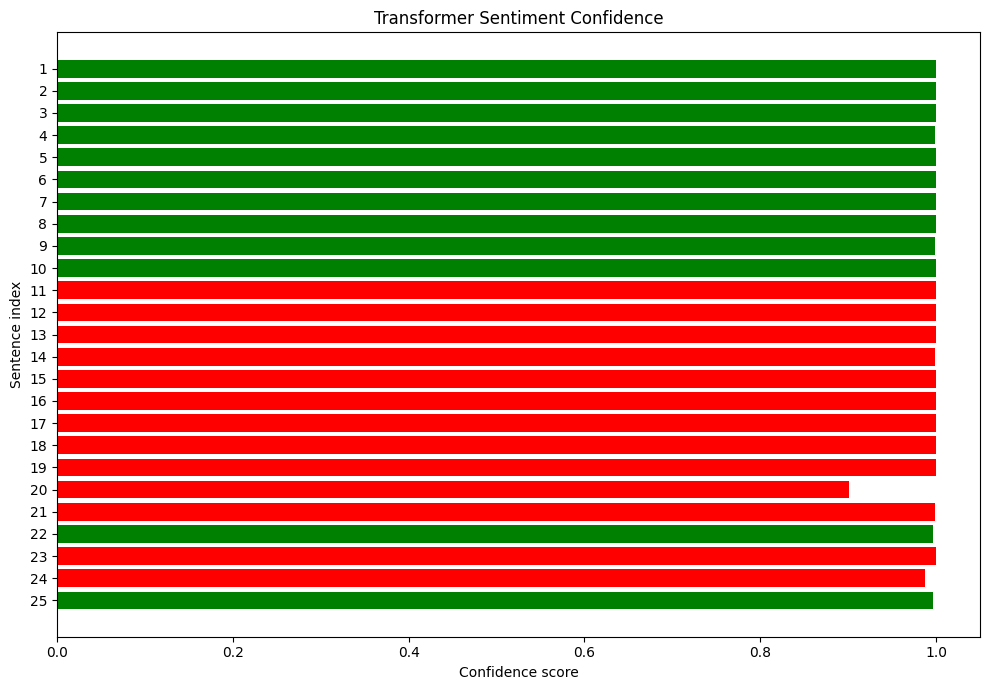

In [38]:
# Plot model confidence for all 25 review sentences
bar_colors = ["green" if label == "POSITIVE" else "red" for label in results_df["Predicted_Label"]]
plt.figure(figsize=(10, 7))
plt.barh(np.arange(1, 26), results_df["Confidence_Score"], color=bar_colors)
plt.yticks(np.arange(1, 26))
plt.xlabel("Confidence score")
plt.ylabel("Sentence index")
plt.title("Transformer Sentiment Confidence")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
results_df.to_csv("transformer_sentiment_results.csv", index=False)

**Transformer reflection**

- A Transformer uses attention to model relationships between words in context.
- Pre-trained means the model learned general language patterns earlier; fine-tuned means it was further trained for a task.
- We can use this model without our own training because its sentiment task has already been fine-tuned.
- The model only predicts positive or negative sentiment, and it may misunderstand Indian-English phrases, slang, sarcasm, or neutral reviews.

## Step 6 — Results Summary, Reflection, and Submission

The results table below uses values generated by the notebook. OpenCV is a preprocessing pipeline, so it has no classification accuracy metric.

In [39]:
# Create the final results summary using metrics calculated above
summary_rows = [
    {"Step / Topic": "ANN", "Task type": "Classification", "Dataset used": f"Pima diabetes ({len(df_diabetes)} rows)", "Key metric": "Test accuracy", "Result achieved": round(float(accuracy_score(y_test, ann_pred)), 4), "Time taken (min)": ""},
    {"Step / Topic": "OpenCV", "Task type": "Preprocessing", "Dataset used": "5 generated sample images", "Key metric": "N/A", "Result achieved": "5 x 5 grid saved", "Time taken (min)": ""},
    {"Step / Topic": "CNN", "Task type": "Classification", "Dataset used": "CIFAR-10 (20,000 train / 4,000 test)", "Key metric": "Test accuracy", "Result achieved": round(float(cnn_accuracy), 4), "Time taken (min)": ""},
    {"Step / Topic": "RNN", "Task type": "Regression", "Dataset used": f"Airline passengers ({len(airline_df)} months)", "Key metric": "Test RMSE", "Result achieved": round(float(rmse_rnn), 2), "Time taken (min)": ""},
    {"Step / Topic": "Transformer", "Task type": "Inference", "Dataset used": "25 custom review sentences", "Key metric": "Correct among 20 clear reviews", "Result achieved": f"{int((correct_mask & clear_mask).sum())}/20", "Time taken (min)": ""}
]
summary_df = pd.DataFrame(summary_rows)
display(summary_df)
summary_df.to_csv("results_summary.csv", index=False)

,Step / Topic,Task type,Dataset used,Key metric,Result achieved,Time taken (min)
0,ANN,Classification,Pima diabetes (768 rows),Test accuracy,0.7013,
1,OpenCV,Preprocessing,5 generated sample images,N/A,5 x 5 grid saved,
2,CNN,Classification,"CIFAR-10 (20,000 train / 4,000 test)",Test accuracy,0.6335,
3,RNN,Regression,Airline passengers (144 months),Test RMSE,32.08,
4,Transformer,Inference,25 custom review sentences,Correct among 20 clear reviews,20/20,


### Written reflection

- The CNN task can be the most time-consuming because it trains on thousands of images over multiple epochs.
- The best model should be judged using its actual test metric and the time needed to build it.
- With more time, I would test dropout or regularisation in the ANN and compare validation performance.
- CNNs use spatial filters to learn image patterns, while a basic ANN treats input features as a flat vector.
- An RNN processes sequences step by step using recurrent state; a Transformer uses attention to relate tokens.
- To make the CNN production-ready, I would add data augmentation, broader evaluation, error analysis, and a tested inference interface.
- With more compute, I would compare model architectures and evaluate them on a larger, representative dataset.